<a href="https://colab.research.google.com/github/halynazhabchyk/nlp_labs/blob/main/NLP_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ПРАКТИЧНА РОБОТА 2: КЛАСИФІКАЦІЯ НОВИН НА ОСНОВІ
ЛОГІСТИЧНОЇ РЕГРЕСІЇ ІЗ БІБЛІОТЕКИ SCIKIT-LEARN


Мета роботи: Реалізувати модель логістичної регресії для класифікації
новинних текстів на основі датасету "20 Newsgroups" із використанням
бібліотеки scikit-learn.


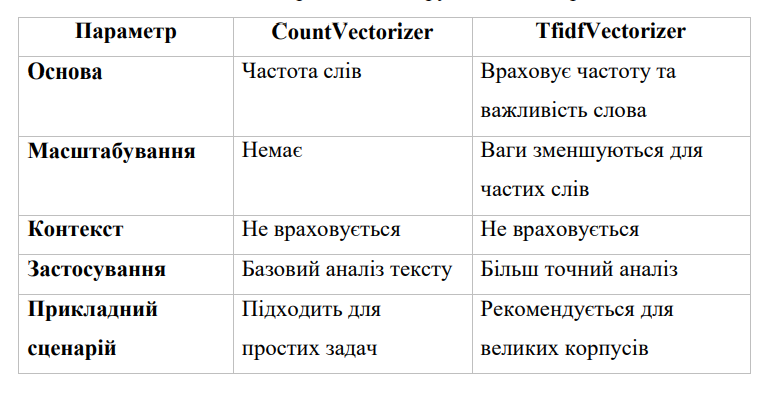

Зберемо код та натренуємо модель наведену у теоретичному описі.

Першим етапом є імпорт бібліотек

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss, f1_score
import time
import numpy as np


Завантажуємо повний датасет текстів, розбитий на
20 категорій.
 remove=('headers', 'footers', 'quotes'): Видаляє зайві частини тексту, щоб
зосередитися на змісті.
 train_test_split: Розділяє дані на тренувальну (70%) та тестову (30%)
вибірки з фіксованим random_state для відтворюваності результатів.

In [ ]:
# Завантаження та попередня обробка даних:
newsgroups = fetch_20newsgroups(subset='all', remove=('headers',
'footers', 'quotes'))
texts = newsgroups.data
labels = newsgroups.target
texts_train, texts_test, labels_train, labels_test = train_test_split(texts,
labels, test_size=0.3, random_state=42)

Налаштування TF-IDF векторизатора

In [ ]:
vectorizer = TfidfVectorizer(min_df=5,
                             max_df=0.8,
                             max_features=20000)


Налаштування логістичної регресії:

In [ ]:
classifier = LogisticRegression(
 solver='saga', # Ефективний оптимізатор для великих датасетів
 max_iter=1000, # Збільшення ітерацій для забезпечення збіжності
 C=1.0, # Гіперпараметр регуляризації (чим менше, тим сильніше регуляризація)
 random_state=42 # Фіксація для відтворюваності
)

pipeline = make_pipeline(vectorizer, classifier)


Навчання моделі:

In [ ]:
pipeline.fit(texts_train, labels_train)

Pipeline(steps=[('tfidfvectorizer',
                 TfidfVectorizer(max_df=0.8, max_features=20000, min_df=5)),
                ('logisticregression',
                 LogisticRegression(max_iter=1000, random_state=42,
                                    solver='saga'))])

In [ ]:
val_preds = pipeline.predict(texts_test)
val_accuracy = accuracy_score(labels_test,val_preds)
print(f"Validation Accuracy (scikit-learn): {val_accuracy:.4f}")


Validation Accuracy (scikit-learn): 0.7131


In [ ]:
train_preds = pipeline.predict(texts_train)
train_accuracy = accuracy_score(labels_train, train_preds)
print(f"Train Accuracy (scikit-learn): {train_accuracy:.4f}")

Train Accuracy (scikit-learn): 0.8827


Результати показують, що модель добре навчається на тренувальних даних, досягаючи точності 88,27%,  на валідаційному наборі точність падає до 71,31%. Загалом, модель має прийнятну точність, але потребує доопрацювання для підвищення узагальнення на тестових даних


Спробуємо додати різні методи
векторизації
 Порівняємо якість класифікації при використанні CountVectorizer і
TfidfVectorizer.
 Для CountVectorizer спробуємо різні параметри ngram_range
Для TfidfVectorizer змінимо параметр max_features - розмір словника



In [ ]:
# Function for training and validating models and saving results
from sklearn.metrics import accuracy_score, log_loss
def train_model(vectorizer,
                classifier,
                texts_train,
                labels_train,
                texts_test,
                labels_test ):
  metrics = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
  pipeline = make_pipeline(vectorizer, classifier)
  pipeline.fit(texts_train, labels_train)


  train_preds = pipeline.predict(texts_train)
  train_accuracy = accuracy_score(labels_train, train_preds)

  train_preds_proba = pipeline.predict_proba(texts_train)
  train_loss = log_loss(labels_train, train_preds_proba)


  val_preds = pipeline.predict(texts_test)
  val_accuracy = accuracy_score(labels_test,val_preds)

  val_preds_proba = pipeline.predict_proba(texts_test)
  val_loss = log_loss(labels_test, val_preds_proba)

  metrics['train_loss'].append(train_loss)
  metrics['train_acc'].append(train_accuracy)

  metrics['test_loss'].append(val_loss)
  metrics['test_acc'].append(val_accuracy)

  print("Train Accuracy:", metrics['train_acc'][0])
  print("Train Loss:", metrics['train_loss'][0])
  print("Test Accuracy:", metrics['test_acc'][0])
  print("Test Loss:", metrics['test_loss'][0])


  return pipeline, metrics



In [ ]:
modes = ['CountVectorizer', 'CountVectorizer_bigram',
         'TfidfVectorizer_5',
         'TfidfVectorizer_10',
         'TfidfVectorizer_20']
# Параметри векторизаторів
vectorizer_params = {
    "max_df": 0.8,
    "min_df": 5,
}
all_results = {}


for mode in modes:
    print(f"\n=== Mode: {mode} ===")

    # Векторизатор
    if mode == 'CountVectorizer':
        vectorizer = CountVectorizer(ngram_range=(1,1), max_features=20000, **vectorizer_params)
    elif mode == 'CountVectorizer_bigram':
        vectorizer = CountVectorizer(ngram_range=(1,2), max_features=20000, **vectorizer_params)
    elif mode == 'TfidfVectorizer_5':
        vectorizer = TfidfVectorizer(max_features=5000, **vectorizer_params)
    elif mode == 'TfidfVectorizer_10':
        vectorizer = TfidfVectorizer(max_features=10000, **vectorizer_params)
    else:  # TfidfVectorizer_20
        vectorizer = TfidfVectorizer(max_features=20000, **vectorizer_params)

    classifier = LogisticRegression(
    solver='saga', # Ефективний оптимізатор для великих датасетів
    max_iter=3000, # Збільшення ітерацій для забезпечення збіжності
    C=1.0, # Гіперпараметр регуляризації (чим менше, тим сильніше регуляризація)
    random_state=42 # Фіксація для відтворюваності
    )

    model, metrics = train_model(vectorizer, classifier,
                                        texts_train, labels_train,
                                        texts_test, labels_test)

    # Зберігаємо результати
    all_results[mode] = {
        "model": model,
        "metrics": metrics
    }


=== Mode: CountVectorizer ===
Train Accuracy: 0.33080654942389326
Train Loss: 2.7874914834023334
Test Accuracy: 0.30509373894587904
Test Loss: 2.8091776742742445

=== Mode: CountVectorizer_bigram ===
Train Accuracy: 0.2689508793208005
Train Loss: 2.8456713363180586
Test Accuracy: 0.24177573399363284
Test Loss: 2.863206506264645

=== Mode: TfidfVectorizer_5 ===
Train Accuracy: 0.8406610066707095
Train Loss: 1.0640015169291834
Test Accuracy: 0.6733286169083834
Test Loss: 1.399285660072461

=== Mode: TfidfVectorizer_10 ===
Train Accuracy: 0.8664342025469982
Train Loss: 1.0472391785566744
Test Accuracy: 0.7021577644145738
Test Loss: 1.3957520348064714

=== Mode: TfidfVectorizer_20 ===
Train Accuracy: 0.8826561552456034
Train Loss: 1.05108695352842
Test Accuracy: 0.7131234524230633
Test Loss: 1.4112141027901157


Бачимо, що використання CountVectorizer дає низбку якість моделі та повільну збіжність, потребуючи більшої кількості ітерацій для досягнення оптимуму, бо просте підрахування частоти слів не враховує їхню важливість у контексті документів, через що точність залишається низькою і модель погано узагальнює.
TfidfVectorizer демонструє вищу ефективність, оскільки враховує як частоту слова в документі, так і його рідкість у корпусі, що дозволяє виділяти більш значущі ознаки.
Крім того, збільшення розміру словника забезпечує кращу точність і зменшення втрат, бо модель отримує більше інформації для розрізнення класів.

Троведемо тестування  моделі TfidfVectorizer_20 на різних категоріях із датасету

In [ ]:
# Завантаження та попередня обробка даних:
themes = ['sci.space','sci.electronics','sci.med']
newsgroups_subset = fetch_20newsgroups(subset='all', categories= themes, remove=('headers','footers', 'quotes'))
texts_subset = newsgroups_subset.data
labels_subset = newsgroups_subset.target
train_subset, test_subset, labels_train_subset, labels_test_subset = train_test_split(texts_subset,
labels_subset, test_size=0.3, random_state=42)

list(newsgroups_subset.target_names)

['sci.electronics', 'sci.med', 'sci.space']

In [ ]:
vectorizer_params = {
    "max_df": 0.8,
    "min_df": 5,
}
all_results = {}
vectorizer_subset = TfidfVectorizer(max_features=20000, **vectorizer_params)
classifier_subset = LogisticRegression(
    solver='saga', # Ефективний оптимізатор для великих датасетів
    max_iter=1000, # Збільшення ітерацій для забезпечення збіжності
    C=1.0, # Гіперпараметр регуляризації (чим менше, тим сильніше регуляризація)
    random_state=42 # Фіксація для відтворюваності
    )

    # Навчання по епохах
model_subset, metrics_subset = train_model(vectorizer_subset, classifier_subset,
                                        train_subset, labels_train_subset,
                                        test_subset, labels_test_subset)



Train Accuracy: 0.9676640926640927
Train Loss: 0.3928659201269439
Test Accuracy: 0.8773903262092239
Test Loss: 0.5133546499646028


Можемо спостерігати, що зі збільшенням кількості категорій у наборі даних точність моделей знижується. Це пов’язано з тим, що при більшій кількості класів зростає складність класифікації, з’являється більше нових прикладів та різноманітних ознак, через що моделі важче правильно узагальнювати.
На менші кількості категорій модель показує вищі результати.

Порівняння моделей. Спробуємо інші класифікатори:


Логістична регресія

In [ ]:
classifier_reg = LogisticRegression(
    solver='lbfgs',
    max_iter=1,
    C=1.0, # Гіперпараметр регуляризації (чим менше, тим сильніше регуляризація)
    random_state=42, # Фіксація для відтворюваності
    warm_start = True
    )
vectorizer_reg = TfidfVectorizer(max_features=20000, **vectorizer_params)

In [ ]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
metrics = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
pipeline = make_pipeline(vectorizer_reg, classifier_reg)
start_time = time.time()
for i in range(1,11):
  classifier_reg.max_iter=i
  pipeline.fit(texts_train, labels_train)


  train_preds = pipeline.predict(texts_train)
  train_acc = accuracy_score(labels_train, train_preds)

  train_proba = pipeline.predict_proba(texts_train)
  train_loss = log_loss(labels_train, train_proba)

  # Test
  test_preds = pipeline.predict(texts_test)
  test_acc = accuracy_score(labels_test, test_preds)

  test_proba = pipeline.predict_proba(texts_test)
  test_loss = log_loss(labels_test, test_proba)

  metrics["train_loss"].append(train_loss)
  metrics["train_acc"].append(train_acc)
  metrics["test_loss"].append(test_loss)
  metrics["test_acc"].append(test_acc)

  print(
          f"Iter {i:02d} | "
          f"train_loss={train_loss:.4f} | "
          f"train_acc={train_acc:.4f} | "
          f"test_loss={test_loss:.4f} | "
          f"test_acc={test_acc:.4f}"
      )
elapsed_time = time.time() - start_time

  # Загальна F1 міра на тесті для останньої моделі
final_test_pred = pipeline.predict(texts_test)
f1 = f1_score(labels_test, final_test_pred, average="macro")

print(f"\nTime: {elapsed_time:.4f}")
print(f"\nFinal F1-score on test set: {f1:.4f}")

Iter 01 | train_loss=2.9696 | train_acc=0.1314 | test_loss=2.9743 | test_acc=0.1127
Iter 02 | train_loss=2.5385 | train_acc=0.3375 | test_loss=2.5894 | test_acc=0.2851
Iter 03 | train_loss=2.4144 | train_acc=0.6152 | test_loss=2.4780 | test_acc=0.5403
Iter 04 | train_loss=1.7857 | train_acc=0.6207 | test_loss=1.9268 | test_acc=0.5508
Iter 05 | train_loss=1.5755 | train_acc=0.7424 | test_loss=1.7443 | test_acc=0.6479
Iter 06 | train_loss=1.3895 | train_acc=0.7485 | test_loss=1.6053 | test_acc=0.6454
Iter 07 | train_loss=1.1120 | train_acc=0.8326 | test_loss=1.4225 | test_acc=0.6889
Iter 08 | train_loss=1.0940 | train_acc=0.8527 | test_loss=1.4136 | test_acc=0.7037
Iter 09 | train_loss=1.0829 | train_acc=0.8638 | test_loss=1.4172 | test_acc=0.7085
Iter 10 | train_loss=1.0555 | train_acc=0.8806 | test_loss=1.4134 | test_acc=0.7142

Time: 82.5979

Final F1-score on test set: 0.7039


Класифікатор випадковий ліс

In [ ]:
from sklearn.ensemble import RandomForestClassifier

metrics_rf = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}
start_time = time.time()
for n_trees in range(1, 11):
    rf = RandomForestClassifier(
        n_estimators=n_trees,
        random_state=42,
        n_jobs=-1
    )

    pipeline_rf = make_pipeline(vectorizer_reg, rf)
    pipeline_rf.fit(texts_train, labels_train)

    # Train
    train_pred = pipeline_rf.predict(texts_train)
    train_acc = accuracy_score(labels_train, train_pred)

    train_proba = pipeline_rf.predict_proba(texts_train)
    train_loss = log_loss(labels_train, train_proba)

    # Test
    test_pred = pipeline_rf.predict(texts_test)
    test_acc = accuracy_score(labels_test, test_pred)

    test_proba = pipeline_rf.predict_proba(texts_test)
    test_loss = log_loss(labels_test, test_proba)

    metrics_rf["train_loss"].append(train_loss)
    metrics_rf["train_acc"].append(train_acc)
    metrics_rf["test_loss"].append(test_loss)
    metrics_rf["test_acc"].append(test_acc)

    print(
        f"Iter {n_trees:02d} | "
        f"train_loss={train_loss:.4f} | "
        f"train_acc={train_acc:.4f} | "
        f"test_loss={test_loss:.4f} | "
        f"test_acc={test_acc:.4f}"
    )

elapsed_time = time.time() - start_time

final_test_pred = pipeline_rf.predict(texts_test)
f1 = f1_score(labels_test, final_test_pred, average="macro")

print(f"\nTime: {elapsed_time:.4f}")
print(f"\nFinal F1-score on test set: {f1:.4f}")



Iter 01 | train_loss=8.5566 | train_acc=0.7364 | test_loss=23.3960 | test_acc=0.3134
Iter 02 | train_loss=2.6913 | train_acc=0.7352 | test_loss=17.8570 | test_acc=0.3108
Iter 03 | train_loss=1.1211 | train_acc=0.8546 | test_loss=14.6276 | test_acc=0.3528
Iter 04 | train_loss=0.6102 | train_acc=0.9128 | test_loss=12.2089 | test_acc=0.4010
Iter 05 | train_loss=0.4735 | train_acc=0.9402 | test_loss=10.2540 | test_acc=0.4358
Iter 06 | train_loss=0.4116 | train_acc=0.9531 | test_loss=9.0216 | test_acc=0.4698
Iter 07 | train_loss=0.3981 | train_acc=0.9621 | test_loss=8.1853 | test_acc=0.4790
Iter 08 | train_loss=0.3937 | train_acc=0.9657 | test_loss=7.4296 | test_acc=0.4855
Iter 09 | train_loss=0.3872 | train_acc=0.9692 | test_loss=6.7239 | test_acc=0.4998
Iter 10 | train_loss=0.3866 | train_acc=0.9702 | test_loss=6.2265 | test_acc=0.5065

Time: 134.4026

Final F1-score on test set: 0.4916


Бачимо, що даний метод показує низькі результати точності та F1-score на тестовій вибірці, тоді як на навчальних даних ці показники високі. Це свідчить про наявність перенавчання, що унеможливлює здатність узагальнювати  нові приклади.


Метод опорних векторів

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline

metrics_svc = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": [],
    "train_time": []
}

C_values = np.logspace(-2, 2, 10)
start_time = time.time()
for C in C_values:
    # Лінійний SVM (швидше за SVC) + калібрування для ймовірностей
    base_svc = LinearSVC(C=C, max_iter=1000)
    svc = CalibratedClassifierCV(base_svc)

    pipeline_svc = make_pipeline(vectorizer_reg, svc)

    pipeline_svc.fit(texts_train, labels_train)
    elapsed_time = time.time() - start_time

    # Train
    train_pred = pipeline_svc.predict(texts_train)
    train_acc = accuracy_score(labels_train, train_pred)
    train_proba = pipeline_svc.predict_proba(texts_train)
    train_loss = log_loss(labels_train, train_proba)

    # Test
    test_pred = pipeline_svc.predict(texts_test)
    test_acc = accuracy_score(labels_test, test_pred)
    test_proba = pipeline_svc.predict_proba(texts_test)
    test_loss = log_loss(labels_test, test_proba)

    # Збереження метрик і часу
    metrics_svc["train_loss"].append(train_loss)
    metrics_svc["train_acc"].append(train_acc)
    metrics_svc["test_loss"].append(test_loss)
    metrics_svc["test_acc"].append(test_acc)
    metrics_svc["train_time"].append(elapsed_time)

    print(
        f"C={C:.4f} | "
        f"train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | "
        f"test_loss={test_loss:.4f} | test_acc={test_acc:.4f} | "
        f"time={elapsed_time:.2f}s"
    )
elapsed_time = time.time() - start_time
# Загальна F1 міра на тесті для останньої моделі
final_test_pred = pipeline_svc.predict(texts_test)
f1 = f1_score(labels_test, final_test_pred, average="macro")
print(f"\nFinal F1-score (macro) on test set: {f1:.4f}")


C=0.0100 | train_loss=0.9665 | train_acc=0.7789 | test_loss=1.2358 | test_acc=0.6788 | time=8.50s
C=0.0278 | train_loss=0.8162 | train_acc=0.8277 | test_loss=1.1463 | test_acc=0.7034 | time=30.30s
C=0.0774 | train_loss=0.6380 | train_acc=0.8814 | test_loss=1.0629 | test_acc=0.7250 | time=55.03s
C=0.2154 | train_loss=0.4775 | train_acc=0.9282 | test_loss=1.0111 | test_acc=0.7333 | time=80.02s
C=0.5995 | train_loss=0.3795 | train_acc=0.9599 | test_loss=1.0045 | test_acc=0.7397 | time=99.73s
C=1.6681 | train_loss=0.3398 | train_acc=0.9728 | test_loss=1.0306 | test_acc=0.7352 | time=123.88s
C=4.6416 | train_loss=0.3325 | train_acc=0.9747 | test_loss=1.0632 | test_acc=0.7255 | time=155.81s
C=12.9155 | train_loss=0.3355 | train_acc=0.9749 | test_loss=1.0871 | test_acc=0.7195 | time=210.28s


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


C=35.9381 | train_loss=0.3396 | train_acc=0.9749 | test_loss=1.1014 | test_acc=0.7174 | time=314.51s


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


C=100.0000 | train_loss=0.3431 | train_acc=0.9749 | test_loss=1.1103 | test_acc=0.7142 | time=460.35s

Final F1-score (macro) on test set: 0.7087


Бачимо, що значення точності та F1-score є дещо вищими за алгоритм логістичної регресії.
Проте, метод опорних векторів є досить витратним за часом, оскільки для великих пакетів даних потрібно обчислювати ймовірності для всіх прикладів, що значно уповільнює роботу. Крім того, через обмежену кількість ітерацій, яку ми встановили через високі обчислювальні витрати, метод не встигає досягти оптимуму, що обмежує його ефективність на великих наборах даних.



Реалізуємо функцію побудови графіків точночті та втрат

In [ ]:
from typing import Dict,List
import matplotlib.pyplot as plt
def plot_loss_curves(results: Dict[str, List[float]]):
    """Plots training curves of a results dictionary.

    Args:
        results (dict): dictionary containing list of values, e.g.
            {"train_loss": [...],
             "train_acc": [...],
             "test_loss": [...],
             "test_acc": [...]}
    """

    # Get the loss values of the results dictionary (training and test)
    loss = results['train_loss']
    test_loss = results['test_loss']

    # Get the accuracy values of the results dictionary (training and test)
    accuracy = results['train_acc']
    test_accuracy = results['test_acc']

    # Figure out how many epochs there were
    epochs = range(len(results['train_loss']))

    # Setup a plot
    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='train_accuracy')
    plt.plot(epochs, test_accuracy, label='test_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend();

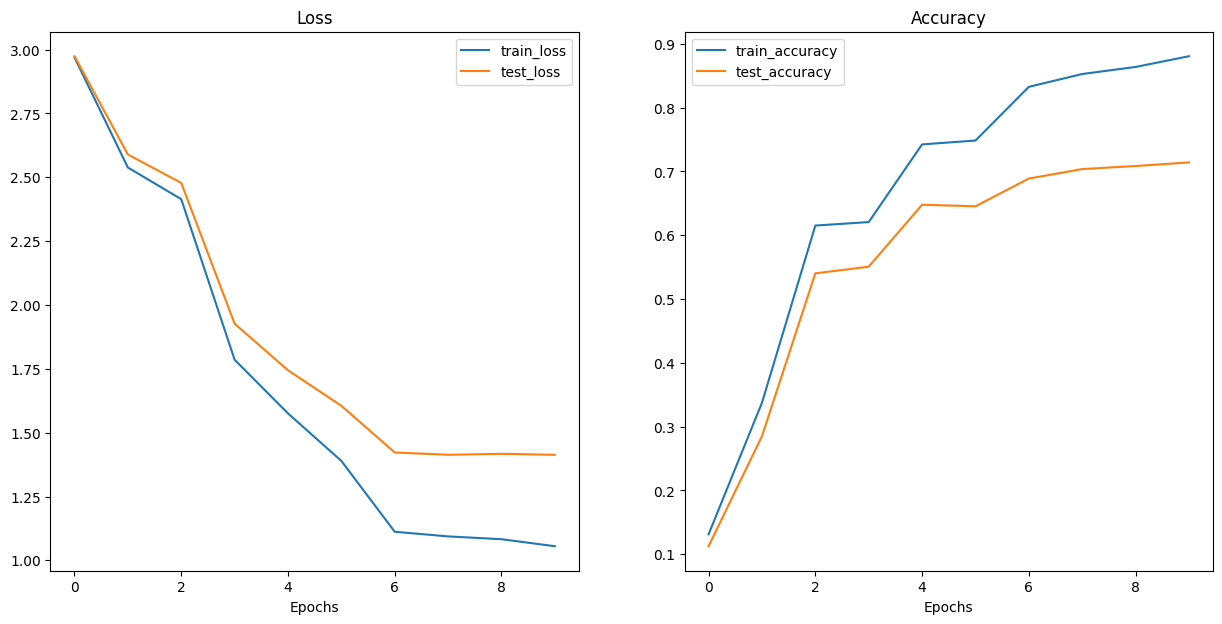

In [ ]:
plot_loss_curves(metrics)

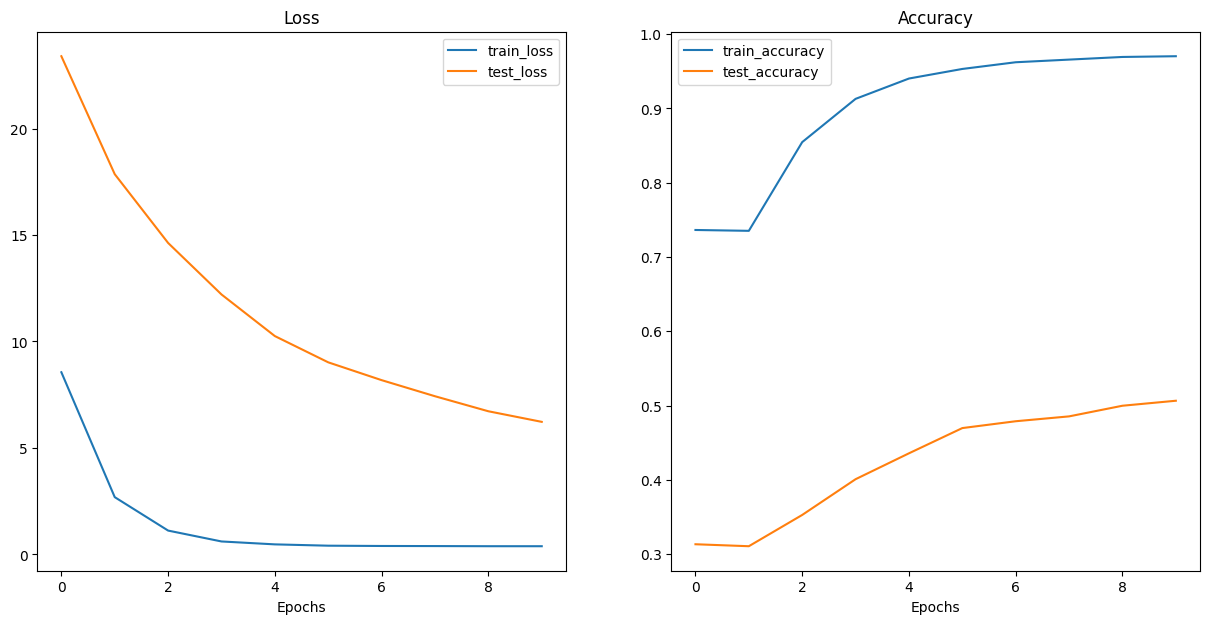

In [ ]:
plot_loss_curves(metrics_rf)

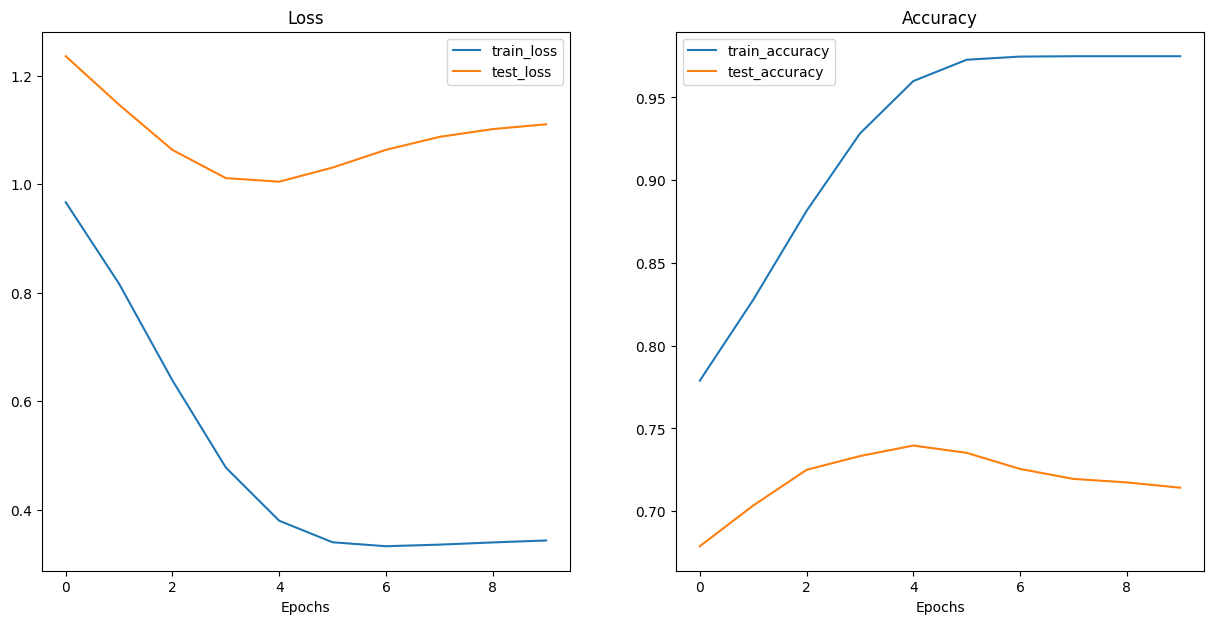

In [ ]:
plot_loss_curves(metrics_svc)

Після аналізу графіків можна стверджувати, що логістична регресія є найефективнішою для класифікації текстів. Вона забезпечує високу точність і низькі значення функції втрат, а також має невеликий розрив між результатами на навчальній і валідаційній вибірках, що свідчить про стабільне навчання та здатність до узагальнення. Додатково, швидка збіжність моделі дозволяє економити час на навчання, що робить її оптимальним вибором для цієї задачі.


Для додаткового аналізу побудуємо матрицю плутанини для моделі логістичної регресії

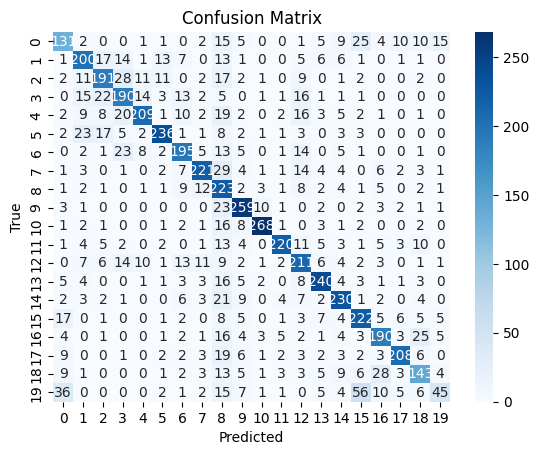

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(labels_test, val_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

 Додатково розрахуємо precision, recall та F1-score для кожної
категорії:

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(labels_test, val_preds, target_names =
newsgroups.target_names))

                          precision    recall  f1-score   support

             alt.atheism       0.58      0.56      0.57       236
           comp.graphics       0.69      0.70      0.69       287
 comp.os.ms-windows.misc       0.70      0.66      0.68       290
comp.sys.ibm.pc.hardware       0.64      0.67      0.65       285
   comp.sys.mac.hardware       0.81      0.67      0.73       312
          comp.windows.x       0.84      0.77      0.80       308
            misc.forsale       0.71      0.71      0.71       276
               rec.autos       0.80      0.73      0.76       304
         rec.motorcycles       0.44      0.80      0.56       279
      rec.sport.baseball       0.77      0.84      0.80       308
        rec.sport.hockey       0.91      0.87      0.89       309
               sci.crypt       0.89      0.76      0.82       290
         sci.electronics       0.63      0.69      0.66       304
                 sci.med       0.80      0.80      0.80       300
         

Найнижчі показники має категорія talk.religion.misc, де F1-score становить лише 0.33 при precision 0.58 і recall 0.23, що свідчить про те, що модель часто пропускає реальні приклади цього класу і помилково відносить до нього тексти інших категорій.
Також складною для класифікації є категорія rec.motorcycles, де спостерігається низька точність (0.44) при високому recall (0.80), тобто модель часто передбачає цей клас помилково для інших прикладів.
Категорії alt.atheism та talk.politics.misc демонструють середні значення F1-score (приблизно 0.57–0.62), що також свідчить про певні труднощі у класифікації.

На мою думку основні причини помилки моделі наступні:
Тексти деяких категорій сильно схожі за словниковим запасом та стилем, наприклад, «talk.religion.misc» може містити загальні релігійні терміни, які також зустрічаються в «soc.religion.christian», через що модель плутає ці класи.
Зокрема, некоректний або нерівномірний розподіл даних у навчальному наборі зменшує можливість моделі навчитися розрізняти рідкісні або менш представлені категорії.
Окрім того, широкий або загальний зміст тем передбачає, що слова з певних категорій можуть зустрічатися і в інших класах, що ускладнює точне передбачення.


Увімкнемо параметр stop_words='english' у векторизаторі, щоб перевірити зміну точності
чи зміниться точність.

In [ ]:
classifier_stop_w = LogisticRegression(
    solver='lbfgs', # Ефективний оптимізатор для великих датасетів
    max_iter=1,
    C=1.0, # Гіперпараметр регуляризації (чим менше, тим сильніше регуляризація)
    random_state=42, # Фіксація для відтворюваності
    warm_start = True
    )
vectorizer_stop_w = TfidfVectorizer(max_features=20000, stop_words='english', **vectorizer_params)

In [ ]:

warnings.filterwarnings("ignore", category=ConvergenceWarning)
metrics = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
pipeline = make_pipeline(vectorizer_stop_w, classifier_stop_w)
start_time = time.time()
for i in range(1,11):
  classifier_stop_w.max_iter=i
  pipeline.fit(texts_train, labels_train)


  train_preds = pipeline.predict(texts_train)
  train_acc = accuracy_score(labels_train, train_preds)

  train_proba = pipeline.predict_proba(texts_train)
  train_loss = log_loss(labels_train, train_proba)

  # Test
  test_preds = pipeline.predict(texts_test)
  test_acc = accuracy_score(labels_test, test_preds)

  test_proba = pipeline.predict_proba(texts_test)
  test_loss = log_loss(labels_test, test_proba)

  metrics["train_loss"].append(train_loss)
  metrics["train_acc"].append(train_acc)
  metrics["test_loss"].append(test_loss)
  metrics["test_acc"].append(test_acc)

  print(
          f"Iter {i:02d} | "
          f"train_loss={train_loss:.4f} | "
          f"train_acc={train_acc:.4f} | "
          f"test_loss={test_loss:.4f} | "
          f"test_acc={test_acc:.4f}"
      )
elapsed_time = time.time() - start_time

  # Загальна F1 міра на тесті для останньої моделі
final_test_pred = pipeline.predict(texts_test)
f1 = f1_score(labels_test, final_test_pred, average="macro")

print(f"\nTime: {elapsed_time:.4f}")
print(f"\nFinal F1-score on test set: {f1:.4f}")

Iter 01 | train_loss=2.9703 | train_acc=0.1554 | test_loss=2.9747 | test_acc=0.1358
Iter 02 | train_loss=2.4965 | train_acc=0.3285 | test_loss=2.5541 | test_acc=0.2779
Iter 03 | train_loss=2.3495 | train_acc=0.7021 | test_loss=2.4206 | test_acc=0.6226
Iter 04 | train_loss=1.5901 | train_acc=0.6371 | test_loss=1.7599 | test_acc=0.5624
Iter 05 | train_loss=1.4528 | train_acc=0.7855 | test_loss=1.6319 | test_acc=0.6877
Iter 06 | train_loss=1.1121 | train_acc=0.8457 | test_loss=1.3980 | test_acc=0.7112
Iter 07 | train_loss=1.0853 | train_acc=0.8642 | test_loss=1.3936 | test_acc=0.7183
Iter 08 | train_loss=1.0612 | train_acc=0.8843 | test_loss=1.3983 | test_acc=0.7230
Iter 09 | train_loss=1.0487 | train_acc=0.8852 | test_loss=1.3933 | test_acc=0.7232
Iter 10 | train_loss=1.0357 | train_acc=0.8924 | test_loss=1.3902 | test_acc=0.7218

Time: 76.0603

Final F1-score on test set: 0.7107


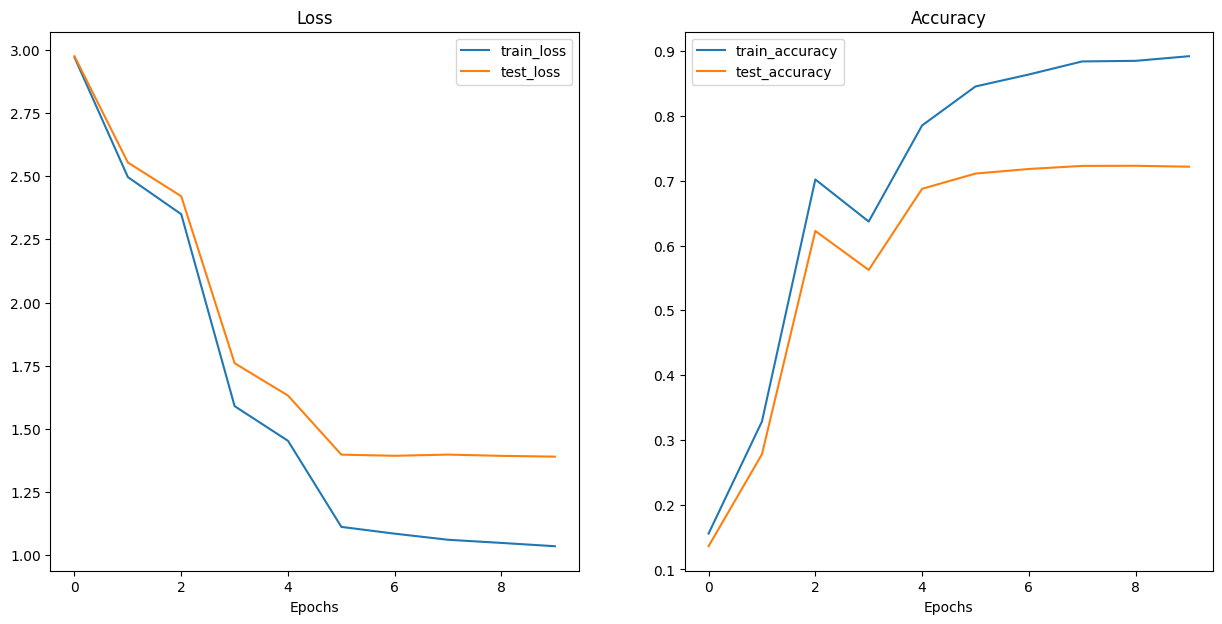

In [ ]:
plot_loss_curves(metrics)

Можна побачити, що додавання даного слова збільшило пояснювальні здатності моделі.
Це видно по поступовому зростанню точності на тестовому наборі від перших ітерацій і до кінця навчання, при одночасному зниженні функції втрат.

Використання stop_words='english' обумовлене тим, що тексти в наборі даних написані англійською мовою. Англійські стоп-слова — це часто вживані слова, які несуть мінімум семантичної інформації для класифікації. Видалення цих слів дозволяє моделі зосередитися на значущих термінах, що реально розрізняють категорії текстів, і таким чином покращує якість передбачень.